<a href="https://colab.research.google.com/github/azaro-1982/Comparation/blob/main/TyFdD_20261_PEC1_CAST_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PAC1: Tipología y fuentes de datos

# Ejercicio 4: Predicción de Churn en Telecomunicaciones (2.5 puntos)

En este ejercicio, exploraremos un conjunto de datos de clientes de una operadora de telefonía para identificar patrones que indiquen si un cliente cancelará su servicio (**Churn**).

### Contexto
La pérdida de clientes (Churn) es uno de los problemas más críticos para las empresas de suscripción. Cuesta mucho más captar a un nuevo cliente que mantener a uno vigente. El objetivo es analizar el comportamiento de los usuarios para tomar decisiones proactivas.

### Tareas a realizar:
1. **Análisis de variables**: Comprobar qué servicios (Internet, Seguridad, Soporte) tienen más impacto en la baja del cliente.
2. **Visualización de permanencia**: Analizar cómo afecta la 'tenure' (antigüedad) a la probabilidad de irse.
3. **Ingeniería de características**: Crear una nueva variable que segmente a los clientes según su gasto mensual.
4. **Comparativa de 5 Modelos de Clasificación**

  En esta parte, entrenaremos 5 modelos diferentes para predecir el Churn y compararemos su rendimiento mediante métricas estándar:
  1. **Logistic Regression** (Baseline)
  2. **Decision Tree Classifier**
  3. **Random Forest Classifier**
  4. **K-Nearest Neighbors (KNN)**
  5. **Support Vector Classifier (SVC)**

  El objetivo es identificar cuál de ellos generaliza mejor con los datos de telecomunicaciones.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Cargamos el dataset de Telco Churn desde el repositorio de IBM
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df_churn = pd.read_csv(url)

# Limpieza básica de datos:
# 1. Convertimos TotalCharges a numérico (las filas vacías se volverán NaN)
df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')

# 2. Eliminamos las filas con valores nulos (normalmente una decena en este dataset)
df_churn.dropna(inplace=True)

print("Dataset cargado correctamente. Dimensiones:", df_churn.shape)
display(df_churn.head())

Dataset cargado correctamente. Dimensiones: (7032, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Tarea 1: Análisis del impacto de los servicios y métodos de pago
Comprueba qué factores tienen más impacto en la baja del cliente. En concreto:
* Compara el **Churn** según el tipo de **servicio de Internet**.
* Analiza si disponer de **soporte técnico** (TechSupport) reduce la tasa de abandono.
* Investiga si algún **método de pago** está especialmente asociado a la pérdida de clientes.

In [ ]:

# TODO
# Compruebo que valores son únicos.
print(df_churn['InternetService'].unique())
print(df_churn['Churn'].unique())


['DSL' 'Fiber optic' 'No']
['No' 'Yes']


**1. Análisis de la tasa de abandono en función del tipo de de servicio de internet.**

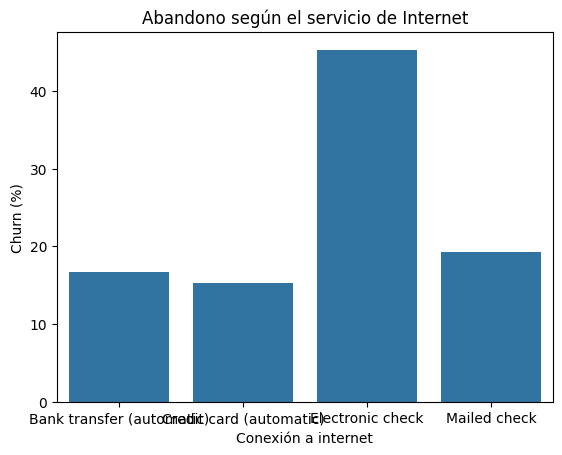

In [ ]:
tipo_pago_churn = pd.crosstab(
    df_churn['PaymentMethod'],
    df_churn['Churn'],
    normalize='index'
) * 100


# Dibujo un gráfico de Barra
sns.barplot(
    x=tipo_pago_churn.index,
    y=tipo_pago_churn['Yes']
)

plt.xlabel('Conexión a internet')
plt.ylabel('Churn (%)')
plt.title('Abandono según el servicio de Internet')
plt.show()

En este caso podemos ver en los resultados que hay una asociación entre el tipo de internet que se contrata. Podemos observar que hay una gran diferencia de abandono entre los clientes que tienen contratado DSL y aquellos que tienen contratados fibra óptcica. Aquellos clientes que tienen contratado DSL presentan una tasa de abandono 23 puntos porcentuales menor a aquellos que tienen fibra.

**2. Analizo este apartado hay que comprobar si el hecho de disponer se soporte técnico está relacionado con la tasa de abandono o churn**


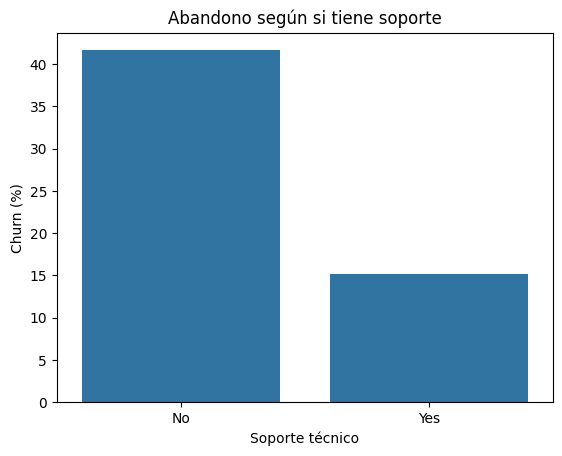

In [ ]:
soporte_churn = pd.crosstab(
    df_churn['TechSupport'],
    df_churn['Churn'],
    normalize = 'index'
) * 100

# En este caso solo necesito aquellos que tienen internet.
soporte_churn = soporte_churn.loc[['No', 'Yes']]

sns.barplot(
    x = soporte_churn.index,
    y = soporte_churn['Yes']
)

## dibujo el gráfico de barra

plt.xlabel('Soporte técnico')
plt.ylabel('Churn (%)')
plt.title('Abandono según si tiene soporte')
plt.show()

Según los gráficos anteriores podemos sacar las siguientes conclusiones:


*   Los clientes que no han dispuesto de soporte técnico presentan la tasa de abandono más alta, alrededor del 41%.
*   Los clientes con soporte técnico presentan una tasa de abandono bastante menor, alrededor del 15%.

En este caso podemos observar que la diferencia de abandonos entre clientes que si tienen soporte técnico de aquellos que no lo tienen es bastante importante.



**3. Análisis de abandonos en función de los métodos de pago**

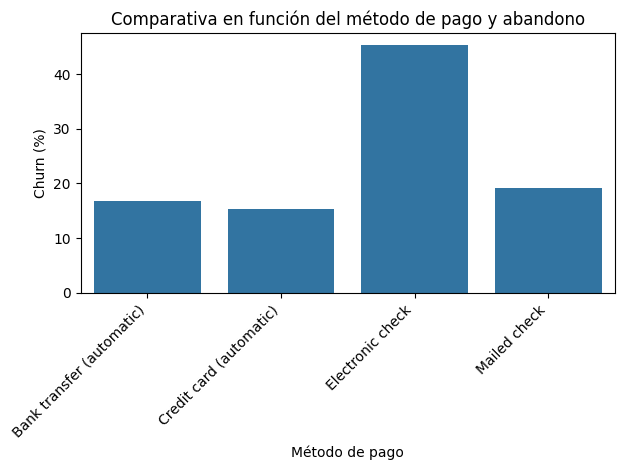

In [ ]:
# Miro los valores únicos de esta tabla.
# print(df_churn['PaymentMethod'].unique())
metodo_pago_churn = pd.crosstab(
    df_churn['PaymentMethod'],
    df_churn['Churn'],
    normalize = 'index'
) * 100


sns.barplot(
    x = metodo_pago_churn.index,
    y = metodo_pago_churn['Yes']
)

## dibujo el gráfico de barra

plt.xlabel('Método de pago')
plt.ylabel('Churn (%)')
plt.title('Comparativa en función del método de pago y abandono')

plt.xticks(rotation=45, ha='right')
plt.tight_layout() # De esta manera no se cortan los textos
plt.show()


En este caso podemos observar como aquellos clientes que suele pagar mediante electric check o cheque electrónico presenta la mayor tasa de abandono, alrededor del 45%. Mientras que los clientes que utilizan otros métodos de pago se encuentran en una horquilla de abandono que se encuentra entre el 15% y 19%.

De ese análisis podemos concluir que existe una relación entre la forma de pago y la tasa de abandono.

Solución:

### Tarea 2: Visualización detallada de la permanencia (Tenure)
La antigüedad del cliente es uno de los mejores predictores del Churn. En esta tarea:
* Crea un gráfico que combine histogramas y curvas de densidad (KDE) para la variable `tenure`, segmentando por `Churn`.
* Identifica visualmente en qué periodos (meses iniciales vs. clientes antiguos) se concentra la mayor parte de las bajas.
* Calcula la media de permanencia para cada grupo (los que se van vs. los que se quedan).

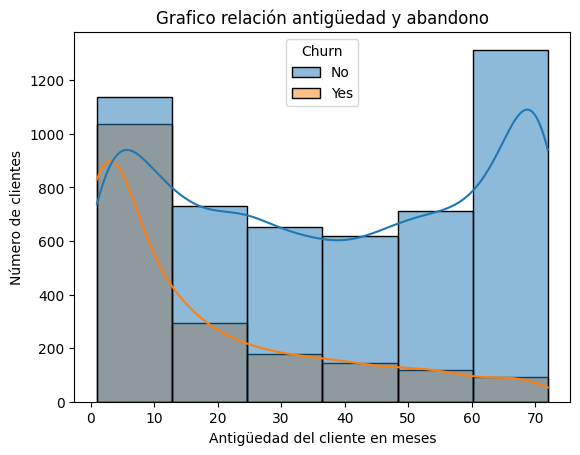

In [ ]:
# TODO
sns.histplot(
    data = df_churn,
    x = 'tenure',
    hue = 'Churn',
    kde = True,
    bins = 6
)

plt.xlabel('Antigüedad del cliente en meses')
plt.ylabel('Número de clientes')
plt.title('Grafico relación antigüedad y abandono')
plt.show()
# TODO

En el gráfico anterior lo he dividido en 6 columnas para que aproximadamente equivalga a un año de antigüedad del cliente.
Según el gráfico anterior podemos observar que la mayoría de las bajas se producen durante el primer año, especialmente en los primeros meses. A partir del segúndo año el número de clientes que abandonan se disminuye de manera considerable.

De este gráfico puedo sacar la conclusión de que existe una relación entre la antigüedad de los clientes y el abandono.

In [ ]:
media_permanencia = df_churn.groupby('Churn')['tenure'].mean()
print('La media de permanencia es \n')
print(round(media_permanencia,2))

La media de permanencia es 

Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64


Podemos ver que la media de permanencia verifica los datos observados en la gráfica. Los clientes que suelen abandonar suelen ser aquellos que tienen una menor antigüedad en la empresa respecto de aquellos que tienen una mayor antigüedad.

Solución:

### Tarea 3: Ingeniería de características (Feature Engineering)
Crea una nueva variable `TotalSpendCategory` que segmente a los clientes en 'Low', 'Medium' y 'High' según el `TotalCharges`.

In [ ]:
df_churn['TotalSpendCategory'] = pd.qcut(
    df_churn['TotalCharges'],
    q = 3,
    labels=['Low','Medium','Hight']
)
display(df_churn.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalSpendCategory
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,bajo
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,medio
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,bajo
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,medio
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,bajo


Solución:

### Tarea 4: Comparativa de Modelos y Análisis de Resultados
Entrena y compara el rendimiento de estos 5 modelos: Logistic Regression, Decision Tree, Random Forest, KNN y SVM.

**Objetivos adicionales:**
* Observa las diferencias entre las métricas de entrenamiento y prueba.
* Redacta una breve conclusión sobre qué modelo consideras más adecuado para este negocio y por qué.

In [ ]:
# 1. Entrena los modelos y muestra los resultados
# TODO
# Para realizar esta actividad tengo que dividir los datos
# para realizar posteriormente los entrenamientos de los modelos
X = df_churn.drop(columns=['Churn', 'customerID'])
y = df_churn['Churn']

# Transformo los valores categóricos
X = pd.get_dummies(X, drop_first=True)

# Dividir los valores en entrenamieto y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. ¿Qué modelo elegirías? ¿Hay alguno que claramente funcione mejor?
# Comenta aquí tus observaciones basándote en los resultados



**1. Modelo Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


# Crear el modelo
modelo_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Entrenar el modelo
modelo_lr.fit(X_train, y_train)

# Calcular las predicciones
pred_train = modelo_lr.predict(X_train)
pred_test = modelo_lr.predict(X_test)

# Mostrar resultados
print("Accuracy entrenamiento:", round(accuracy_score(y_train, pred_train),4))
print("Accuracy prueba:", round(accuracy_score(y_test, pred_test), 4))

Accuracy entrenamiento: 0.8043
Accuracy prueba: 0.8038


**2. Modelo Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

modelo_dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
modelo_dt.fit(X_train, y_train)

pred_train = modelo_dt.predict(X_train)
pred_test = modelo_dt.predict(X_test)

print("Accuracy en entrenamiento:", round(accuracy_score(y_train, pred_train),4))
print("Accuracy en prueba:", round(accuracy_score(y_test, pred_test), 4))

Accuracy en entrenamiento: 0.802
Accuracy en prueba: 0.7783


**3. Modelo Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(random_state=42)

#Entrenar el modelo
modelo_rf.fit(X_train, y_train)

#Calcular las predicciones
pred_train = modelo_rf.predict(X_train)
pred_test = modelo_rf.predict(X_test)

print("Accuracy en entrenamiento:", round(accuracy_score(y_train, pred_train),4))
print("Accuracy en prueba:", round(accuracy_score(y_test, pred_test), 4))

Accuracy en entrenamiento: 0.9988
Accuracy en prueba: 0.7896


**4. Modelo KNN**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
# Con esta libería calculo el porcentaje de predicciones correctas
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Para KNN necesito que los datos estén normalizados.
scaler = StandardScaler()
X_datos_escalados = scaler.fit_transform(X_train)
X_test_escalados = scaler.transform(X_test)

# Ahora creo el modelo
knn = KNeighborsClassifier(n_neighbors=5)
# Entreno el modelo
y_pred_knn = knn.fit(X_datos_escalados, y_train)

# Realizar las predicciones
y_pred_knn = knn.predict(X_test_escalados)

# Evaluo el modelo
accuracy_train = knn.score(X_datos_escalados, y_train)
accuracy_test = accuracy_score(y_test, y_pred_knn)

print("Accuracy entrenamiento: ", round(accuracy_train, 4))
print("Accuracy resultados test: ", round(accuracy_test, 4))

Accuracy entrenamiento:  0.8348
Accuracy resultados test:  0.7534


**5. Modelo SVM**

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Tengo que estandarizar los datos
scaler_svm = StandardScaler()

X_train_svm = scaler_svm.fit_transform(X_train)
X_test_svm = scaler_svm.transform(X_test)

# Ahora puedo crear el modelo
svm = SVC(kernel='rbf', C=1.0)

# Entreno mi modelo
svm.fit(X_train_svm, y_train)

y_pred_svm = svm.predict(X_test_svm)
# Tengo que evaluar el modelo
accuracy_train_svm = svm.score(X_train_svm, y_train)
accuracy_test_svm = accuracy_score(y_test, y_pred_svm)

print("Accuracy entrenamiento:", round(accuracy_train_svm, 4))
print("Accuracy prueba:", round(accuracy_test_svm, 4))

Accuracy entrenamiento: 0.8215
Accuracy prueba: 0.7868


<div style="text-align: center;">
  <h2>Comparación de modelos de Machine Learning</h2>
</div>
Después de haber realizado los distintos modelos elegiría el modelo de **Regresión Logística**, ya que este presenta una mayor precisión que los otros modelos que se han realizado (80.38%).

El principal factor que me ha llevado a tomar esta decisión es la diferencia mínima que hay entre los resultados de entrenamientos y la prueba. Esto indica que el modelo no muestra señales de sobrejustes a diferencia del Modelo **Random Forest**. En este último modelo vemos como hay una gran diferencia entre los resultados obtenidos en con los datos de entrenamiento y as pruebas.

**La conclusión que saco es que el modelo de Regresión Logística sería la mejor opción de los distintos modelos.**

## Ejercicio 5: Análisis del Umbral en la Matriz de Confusión (2.5 puntos)

### Enunciado
En este ejercicio, exploraremos cómo el cambio del umbral de probabilidad (threshold) afecta directamente a los resultados de una matriz de confusión y sus métricas derivadas en un modelo de clasificación binaria.

Contextualizaremos el análisis en un modelo predictivo diseñado para determinar si una mujer está **embarazada** basándose en diversos indicadores. Este es un caso de estudio ideal para analizar los compromisos entre Precisión y Recall, ya que los costes de un Falso Positivo y un Fals Negativo son muy diferentes según la aplicación (médica o de marketing).


### Tareas a realizar:

1. **Entrenamiento y Probabilidades**: Entrenaremos un modelo de Regresión Logística y calcularemos las **probabilidades** de la clase positiva (embarazada) para el conjunto de prueba.
2. **Función de Métricas**: Crearemos una función llamada `calculate_metrics_at_threshold` que reciba las probabilidades y un umbral variable, y devuelva los valores TP, TN, FP, FN así como la Precisión y el Recall.
3. **Experimentación**: Iteraremos sobre 100 umbrales diferentes (de 0 a 1) y almacenaremos los resultados en un DataFrame.
4. **Visualización**: Generaremos un gráfico que muestre la curva de Precisión, Recall y F1-score en función del umbral.
5. **Interpretación**: Responderemos a la pregunta final sobre qué umbral elegiríamos para un escenario de ventas de productos para bebés de alto valor.

Creación de los datos:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.datasets import make_classification

# 1. Generar un conjunto de datos sintético
# Utilizaremos make_classification para crear datos con dos clases.

X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_redundant=0,
                           n_clusters_per_class=1, random_state=42, flip_y=0.1, weights=[0.9, 0.1])

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Distribución de la clase en y_train: {np.bincount(y_train)}")
print(f"Distribución de la clase en y_test: {np.bincount(y_test)}")

Shape de X_train: (700, 10)
Shape de X_test: (300, 10)
Distribución de la clase en y_train: [596 104]
Distribución de la clase en y_test: [255  45]


Ahora, entrenaremos un modelo de Regresión Logística con los datos de entrenamiento y obtendremos las probabilidades de predicción para los datos de prueba. Estas probabilidades son cruciales para poder jugar con los umbrales.

In [ ]:
# 2. Entrenar un modelo de Regresión Logística
model =LogisticRegression(max_iter=1000)#TODO

model.fit(X_train, y_train)
# 3. Calcular las probabilidades de predicción para la clase positiva
# Las probabilidades retornan [probabilidad_clase_0, probabilidad_clase_1]
# Nos interesa la probabilidad de la clase 1 (positiva)

y_pred_proba = model.predict_proba(X_test)[:,1]# TODO

print(f"Primeras 5 probabilidades de predicción: {y_pred_proba[:5]}")

Primeras 5 probabilidades de predicción: [0.01825831 0.05109291 0.17095127 0.08577791 0.07876549]


Solución:

### Entendiendo la Matriz de Confusión y las Métricas

La **Matriz de Confusión** es una tabla que se utiliza para describir el rendimiento de un modelo de clasificación en un conjunto de datos de prueba, donde se conocen los valores verdaderos. Se divide en cuatro componentes:

- **True Positives (TP)**: Predicciones positivas correctas.
- **True Negatives (TN)**: Predicciones negativas correctas.
- **False Positives (FP)**: Predicciones positivas incorrectas (Error de Tipo I).
- **False Negatives (FN)**: Predicciones negativas incorrectas (Error de Tipo II).

A partir de esta matriz, podemos calcular diversas métricas de rendimiento:

- **Exactitud (Accuracy)**: $(TP + TN) / (TP + TN + FP + FN)$
- **Precisión (Precision)**: $TP / (TP + FP)$
- **Recall (Sensibilidad o Exhaustividad)**: $TP / (TP + FN)$
- **F1-score**: $2 \times (Precision \times Recall) / (Precision + Recall)$

In [ ]:
# 4. Función para calcular la matriz de confusión y las métricas para un umbral dado
def calculate_metrics_at_threshold(y_true, y_pred_proba, threshold):
    y_pred = (y_pred_proba >= threshold).astype(int)
    # Esta la matriz de confusión planteada:
    tn, fp, fn,tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()

    # Calculo las métricas:
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    return tp, tn, fp, fn, accuracy, precision, recall, f1

# Ejemplo de uso de la función con un umbral por defecto de 0.5
threshold_default = 0.5
tp, tn, fp, fn, acc, prec, rec, f1 = calculate_metrics_at_threshold(y_test, y_pred_proba, threshold_default)

# TODO: printea las diferentes métricas
print("Los valores TP:", tp,"\n")
print("Los valores TN:", tn,"\n")
print("Los valores FP:", fp,"\n")
print("Los valores FN:", fn,"\n")
print("Accuracy:", acc,"\n")
print("Precision:", prec,"\n")
print("Recall:", rec,"\n")
print("F1-score:", f1,"\n")

Los valores TP: 24 

Los valores TN: 254 

Los valores FP: 1 

Los valores FN: 21 

Accuracy: 0.9266666666666666 

Precision: 0.96 

Recall: 0.5333333333333333 

F1-score: 0.6857142857142857 



Solución:

Ahora, iteraremos a través de un rango de umbrales desde 0.0 hasta 1.0 y almacenaremos las métricas resultantes para cada umbral. Esto nos permitirá observar cómo el umbral influye en el rendimiento del modelo.

In [ ]:
# 5. Iterar sobre un rango de umbrales
thresholds = np.linspace(0, 1, 100)

accuracies = []
precisions = []
recalls = []
f1_scores = []
tps = []
tns = []
fps = []
fns = []

for t in thresholds:
    # TODO
    tp, tn, fp, fn, acc, prec, rec, f1 = calculate_metrics_at_threshold(
        y_test, y_pred_proba, t
    )
    accuracies.append(acc)
    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)
    tps.append(tp)
    tns.append(tn)
    fps.append(fp)
    fns.append(fn)

# Crear un DataFrame para una fácil visualización
metrics_df = pd.DataFrame({
    #TODO
    'Threshold': thresholds,
    'Accuracy': accuracies,
    'Precision': precisions,
    'Recall': recalls,
    'F1': f1_scores,
    'TP': tps,
    'TN': tns,
    'FP': fps,
    'FN': fns
})

display(metrics_df.head(10))

,Threshold,Accuracy,Precision,Recall,F1,TP,TN,FP,FN
0,0.000000,0.150000,0.150000,1.000000,0.260870,45,0,255,0
1,0.010101,0.153333,0.148148,0.977778,0.257310,44,2,253,1
2,0.020202,0.213333,0.157706,0.977778,0.271605,44,20,235,1
3,0.030303,0.286667,0.166008,0.933333,0.281879,42,44,211,3
4,0.040404,0.356667,0.178261,0.911111,0.298182,41,66,189,4
5,0.050505,0.443333,0.195000,0.866667,0.318367,39,94,161,6
6,0.060606,0.523333,0.218391,0.844444,0.347032,38,119,136,7
7,0.070707,0.573333,0.235669,0.822222,0.366337,37,135,120,8
8,0.080808,0.636667,0.264706,0.800000,0.397790,36,155,100,9
9,0.090909,0.673333,0.280992,0.755556,0.409639,34,168,87,11


Solución:

### Visualización de las Métricas en función del Umbral

Con los datos de las métricas para cada umbral, podemos crear gráficos para entender visualmente los compromisos. Normalmente, a medida que aumentamos el umbral:

- La **Precisión** tiende a aumentar (somos más 'selectivos' con nuestras predicciones positivas).
- El **Recall** tiende a disminuir (perdemos más casos positivos reales porque somos más estrictos).
- El **F1-score** a menudo tiene un punto dulce donde se equilibran Precisión y Recall.

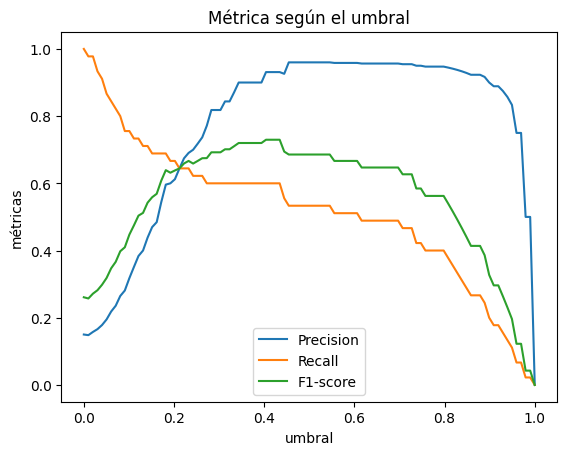

In [ ]:
# 6. Visualitzar com canvien la Precisió, el Recall i l'F1-score amb el llindar
import matplotlib.pyplot as plt

plt.plot(metrics_df['Threshold'], metrics_df['Precision'], label='Precision')
plt.plot(metrics_df['Threshold'], metrics_df['Recall'], label='Recall')
plt.plot(metrics_df['Threshold'],metrics_df['F1'], label='F1-score')

plt.xlabel('umbral')
plt.ylabel('métricas obtenidas')
plt.title('Métrica según el umbral')
plt.legend()
plt.show()

Solución

### 7. Conclusiones y Pregunta de Reflexión

**Pregunta de reflexión:**

Imagina que trabajas para una marca de lujo de productos para bebés. El coste de enviar un kit de bienvenida físico a una posible futura madre es muy elevado (Falso Positivo), pero cada nueva clienta ganada es extremadamente valiosa.

Por otro lado, si el contexto fuese un diagnóstico médico, no detectar un embarazo (Falso Negativo) podría comportar riesgos si la madre toma medicación contraindicada.

**Teniendo en cuenta el gráfico anterior:**
1. ¿Qué umbral de probabilidad elegirías para la campaña de marketing de lujo?
2. ¿Cuál elegirías para el uso médico?
3. ¿Qué error (FP o FN) consideras más crítico en cada uno de los dos casos?

**En este caso se nos plantean 3 escenarios distintos.**

1. En el primer caso se plantea una campaña de marketing de lujo. Desde mi punto de vista, en este caso debe de primar la precisión con lo cual elegiría un umbral de 0.5, ya que, según el gráfico que he realizado anteriormente la precisión ronda el 95%. Esto nos va a permitir reducir los falsos positivos y conseguiremos reducir el envío de kits a aquellas mujeres que no estén embarazadas reduciendo los costes.

2. En el segundo caso debe de primar encontrar el mayor número de mujeres embarazadas, con lo cual, debe de primar la exhaustibidad para evitar pasar mujeres embarazadas y que tanto la mujer como el feto pudieran presentar riesgos. En conclusión, para este caso que se presenta impodría un umbral que estuviera entorno al 0.1 ya que estaría entorno al 80%.

3. ¿Qué error (FP o FN) consideras más crítico en cada uno de los dos casos?

*   En el caso del marketing el mayor problema que puede presentar es el número de FN ya que esto produciría unos costes elevados a la hora de enviar los productos.
*   A nivel médico, el error que podría considerarse más grave es el de los falsos negativos, ya que estos podrían poner en riesgo tanto a las madres como a los fetos.


# Enunciado 6: (2 puntos)

Ejercicio abierto de análisis de datos en python

#### Objetivo
El objetivo de este ejercicio es buscar un conjunto de datos en formato CSV, importarlo como DataFrame en Pandas, y realizar un análisis gráfico y estadístico con diversas visualizaciones.

#### Instrucciones
Busca un archivo CSV:

* Encuentra un conjunto de datos en formato .csv en portales como Kaggle, data.gov u otros repositorios de datos abiertos.
* Asegúrate de que contenga variables numéricas y categóricas.
* Cárgalo en un DataFrame con pandas.read_csv().

##### Tareas a realizar:

1. Visualización Boxplot
2. Visualización Barplot
3. Visualización Scatterplot
4. Regresión lineal
5. Visualización Gráfico libre
6. Conclusiones: resume los principales hallazgos.

In [41]:
import pandas as pd
# df = pd.read_csv('/content/tennis_matches_2014_2025.csv')
df = pd.read_csv('/content/googleplaystore.csv')
df.head()

,n,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,7--Jan--18,1.0.0,4.0.3 and up
1,1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15--Jan--18,2.0.0,4.0.3 and up
2,2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,1--Aug--18,1.2.4,4.0.3 and up
3,3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,8--Jun--18,Varies with device,4.2 and up
4,4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,20--Jun--18,1.1,4.4 and up


In [42]:
# Compruebo que los valores que tiene nan y el tipo de variables que contiene
print(df.isnull().sum())
print(df.dtypes)

n                    0
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64
n                   int64
App                object
Category           object
Rating            float64
Reviews             int64
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object


In [43]:
"""
Cómo en las columnas Type, Current Ver y Android ver hay pocos datos
los voy a borrar.
También voy a sustituir los valores nan de la columna Rating por la mediana
de los valores
"""
df = df.dropna(subset=['Type','Current Ver', 'Android Ver'])
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
print(df.isnull().sum())
print("Las valores de las 10 primeras filas son\n")
df.head()

n                 0
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64
Las valores de las 10 primeras filas son



,n,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,7--Jan--18,1.0.0,4.0.3 and up
1,1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15--Jan--18,2.0.0,4.0.3 and up
2,2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,1--Aug--18,1.2.4,4.0.3 and up
3,3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,8--Jun--18,Varies with device,4.2 and up
4,4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,20--Jun--18,1.1,4.4 and up


**1. Boxplot para valorar la aplicación según el tipo de aplicación**

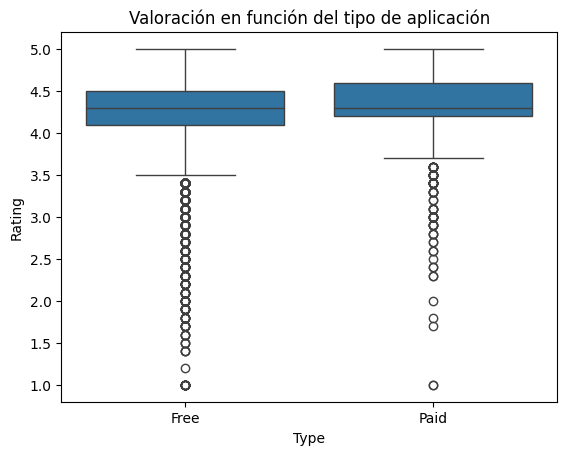

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x='Type', y='Rating')
plt.title('Valoración en función del tipo de aplicación')
plt.show()

**2. Barplot para ver las visualizaciones en función de la categoría.**

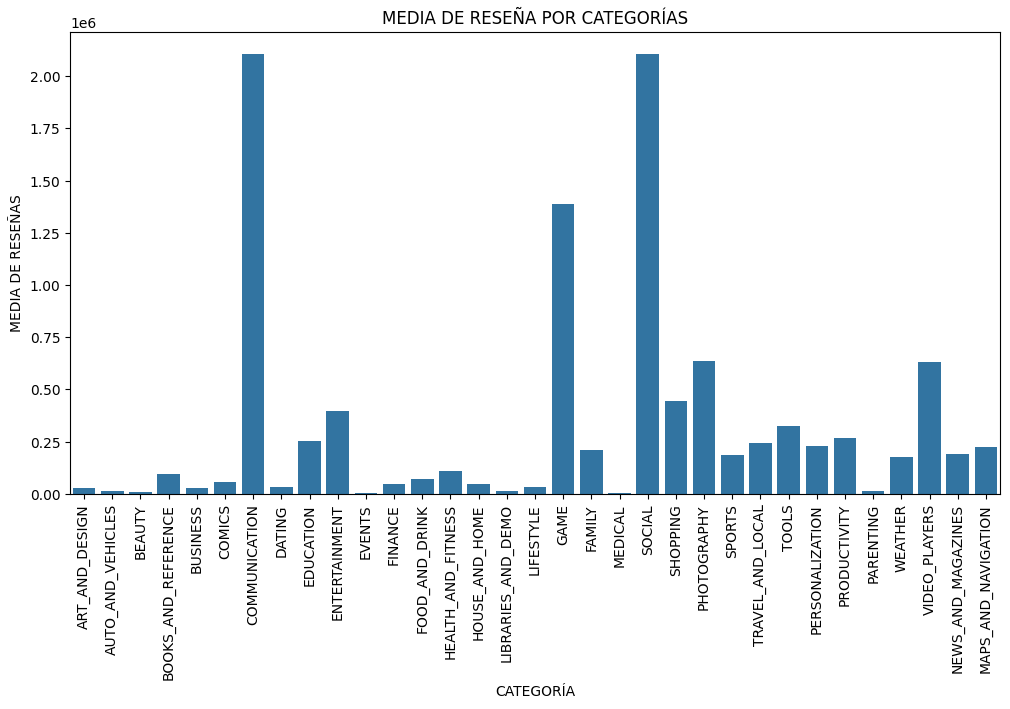

In [55]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Category', y='Reviews', errorbar=None)
plt.xticks(rotation=90)
plt.xlabel('CATEGORÍA')
plt.ylabel('MEDIA DE RESEÑAS')
plt.title('MEDIA DE RESEÑA POR CATEGORÍAS')
plt.show()

**3. Scatterplot que relaciona las visualizaciones con el rating de la aplicación.**

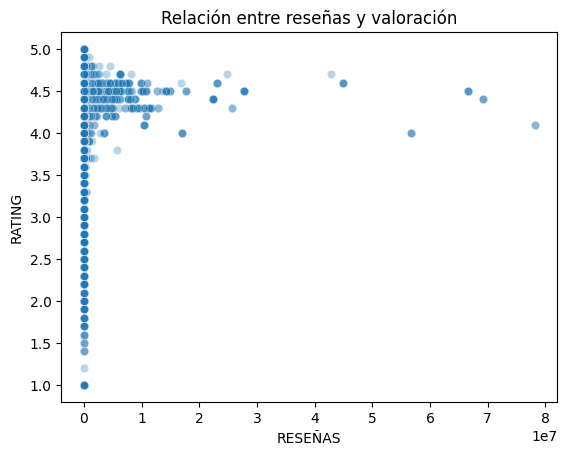

In [53]:
sns.scatterplot(data=df, x='Reviews', y='Rating', alpha=0.3)
plt.xlabel('RESEÑAS')
plt.ylabel('RATING')
plt.title('Relación entre reseñas y valoración')
plt.show()

**4. Modelo de regresión lineal**

In [50]:
from sklearn.linear_model import LinearRegression


X = df[['Reviews']]
Y = df[['Rating']]
modelo = LinearRegression()

# Entreno el modelo
modelo.fit(X, Y)

print("Pendiente de la recta:", modelo.coef_[0])
print("Intercepción:", modelo.intercept_)
print(f"R^2: {modelo.score(X,Y)}")

Pendiente de la recta: [1.03617922e-08]
Intercepción: [4.20190343]
R^2: 0.003990654623381329


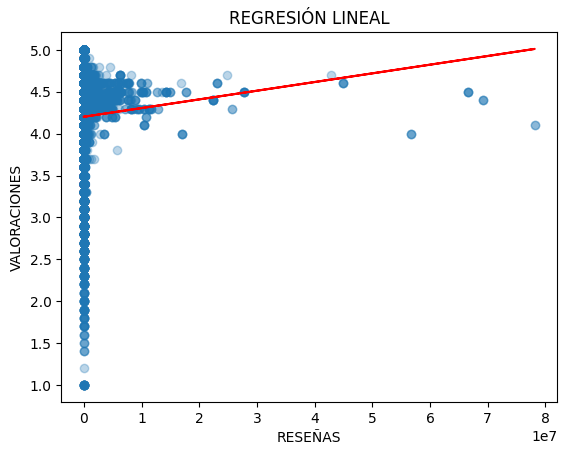

In [54]:
import matplotlib.pyplot as plt

Y_pred = modelo.predict(X)
plt.scatter(X['Reviews'], Y, alpha=0.3, label='Datos')

plt.plot(X['Reviews'], Y_pred, color='red', label='Regresión lineal')
plt.xlabel('RESEÑAS')
plt.ylabel('VALORACIONES')
plt.title('REGRESIÓN LINEAL')
plt.show()

**5. Gráfico libre**

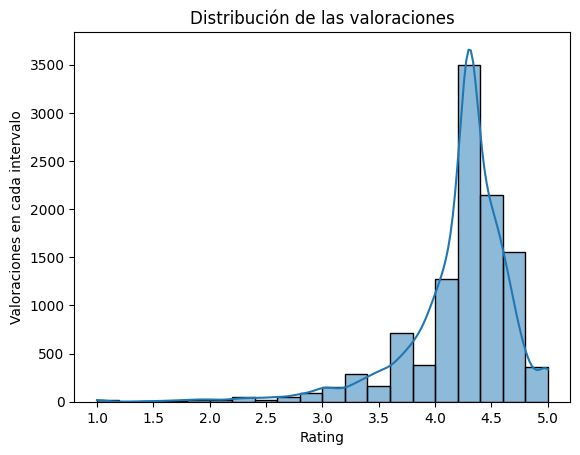

In [52]:
import seaborn as sns

sns.histplot(data=df, x='Rating', bins=20, kde=True)
plt.xlabel('Rating')
plt.ylabel('Valoraciones en cada intervalo')
plt.title("Distribución de las valoraciones")
plt.show()

**6. Conclusiones:**

He realizado el análisis de los datos de las apicaciones de Google Play. Para este análisis se me han ido pidiendo diferentes visualizaciones:


**1.   Boxplot**: En este fráfico se pueden observar que las aplicaciones gratuítas presentan valoraciones similares a aquellas que son de pago. No se puede valorar que existan diferencias reseñables entre ambos grupos.
**2.   Barplot:** En este caso se ve claramente como destacan dos categorías: COMMUNICATION y SOCIAL. Estas aplicaciones destacan en el número de reseñas recibidas.
**3.   Scatterplot:** En este caso no se puede ver que haya una relación lineal entre las reseñas y las valoraciones.
**4.   Regresión linea:** Este modelo presenta un coeficiente R^2 muy bajo, con lo cual, solamente explicaría el 0.4% de las variabilidad de las valoraciones.
**5.   Histograma:** En este gráfico se puede observar como las mayoría de las aplicaciones presentan una puntuación alta. Podemos observar que tiene una asimetría hacia la izquierda y que hay pocas aplicaciones con puntuaciones bajas (por debajo de 3.5)